
# 04 — The layout artifacts, and why there are two of them

**Two GDS files, two different kinds of thing, two different labels.** This
notebook exists partly to make that distinction impossible to miss.

| File | What it is | Label used everywhere |
|---|---|---|
| `gds/idaten_concept_mask/` | A 5 mm x 5 mm magnonic die written with `gdstk`: bus, nanomagnet array at `a` = 200 nm, CPW launch/detect, alignment marks | **CONCEPT MASK - no PDK exists for hematite or LiNbO3 patterning.** Dimensioned and nanometre-accurate, but *not* a manufacturable mask set. |
| `gds/idaten_sky130/` | OpenROAD Flow Scripts / SKY130 digital tier, produced by a real open-flow run | **PDK-backed open-flow layout.** The physical instantiation of `P0` and the `Ck` configuration switches. |

The concept mask is a **statement of intent with nanometre-accurate geometry**.
The SKY130 layout is a **foundry-recognizable artifact**. Presenting them as
equivalent would be dishonest; presenting only the concept mask to a foundry
would be useless.

**Evidence tags.** `(L)` literature · `(S)` simulated here · `(E)` engineering
estimate · `(A)` predicted.


In [1]:

import json, os, subprocess, sys
from pathlib import Path

REPO = Path.cwd()
if not (REPO / "tools").exists():
    REPO = Path(os.path.dirname(os.path.dirname(os.path.abspath("."))))
print("repo root:", REPO)
print("cwd      :", os.getcwd())

import numpy as np
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
import klayout.db as db
print("klayout", db.__version__ if hasattr(db, "__version__") else "0.30.13")


repo root: C:\Users\OSINOR TRILLIONS\Downloads\idaten-architecture
cwd      : C:\Users\OSINOR TRILLIONS\Downloads\idaten-architecture


klayout 0.30.13



## 1. Regenerate the concept mask from source

The mask is generated by a script, so it is fully reproducible and the
geometry is auditable in code rather than trusted as a binary.


In [2]:

cmd = [sys.executable, str(REPO / "tools" / "generate_concept_mask.py"),
       "--out", str(REPO / "gds" / "idaten_concept_mask")]
print("$", " ".join(cmd))
r = subprocess.run(cmd, capture_output=True, text=True)
print(r.stdout[-1200:] if r.stdout else "")
if r.returncode != 0:
    print("STDERR:", r.stderr[-2000:])
    raise RuntimeError("concept mask generation failed")


$ C:\Users\OSINOR TRILLIONS\AppData\Local\Microsoft\WindowsApps\PythonSoftwareFoundation.Python.3.13_qbz5n2kfra8p0\python.exe C:\Users\OSINOR TRILLIONS\Downloads\idaten-architecture\tools\generate_concept_mask.py --out C:\Users\OSINOR TRILLIONS\Downloads\idaten-architecture\gds\idaten_concept_mask


0,
      "purpose": "MG_PHASE",
      "assumption": "phase shifter / tuning region"
    },
    "12": {
      "datatype": 0,
      "purpose": "MG_NL",
      "assumption": "non-linear pinning-site array (the weight landscape)"
    },
    "13": {
      "datatype": 0,
      "purpose": "MG_SOT",
      "assumption": "spin-orbit / spin-torque transducer"
    },
    "14": {
      "datatype": 0,
      "purpose": "MG_MTJ",
      "assumption": "switchable nanomagnet cell (the M_k write target)"
    },
    "15": {
      "datatype": 0,
      "purpose": "MG_RAIL",
      "assumption": "configuration rail (C_k distribution)"
    },
    "20": {
      "datatype": 0,
      "purpose": "CPW",
      "assumption": "coplanar waveguide, launch and detect"
    },
    "30": {
      "datatype": 0,
      "purpose": "ALIGN",
      "assumption": "optical alignment marks"
    },
    "40": {
      "datatype": 0,
      "purpose": "DIE",
      "assumption": "die outline / scribe"
    },
    "50": {
      "datatype": 0,


In [3]:

meta = json.loads((REPO / "gds" / "idaten_concept_mask" / "concept_mask_meta.json").read_text())
print(json.dumps({k: v for k, v in meta.items() if k != "layers"}, indent=2))


{
  "file": "idaten_concept_mask.gds",
  "label": "CONCEPT MASK - no PDK exists for hematite/LiNbO3 patterning",
  "not_a_manufacturable_mask_set": true,
  "die_um": [
    5000.0,
    5000.0
  ],
  "grid_um": 5.0,
  "unit_m": 1e-06,
  "precision_m": 1e-09,
  "bus_width_um": 2.0,
  "array_pitch_um": 0.2,
  "array_elements": 13000,
  "pinning_sites": 10400,
  "cell_nm": [
    100,
    20
  ],
  "cpw_centre_um": 2.1
}



## 2. Read it back with KLayout and audit the geometry

The point of this section is that the numbers in the metadata are **checked
against the file**, not asserted. If the generator and the file disagree, the
file is wrong.

Checks performed:

1. the die is 5 mm x 5 mm;
2. the bus waveguide is the stated width;
3. the nanomagnet elements are 100 nm x 20 nm at a 200 nm pitch;
4. the nanomagnet count matches the metadata;
5. the CPW centre conductor is 2.1 µm wide;
6. every layer declared in the metadata is present in the file.

KLayout returns coordinates in database units, so they are multiplied by
`dbu` to get micrometres.


In [4]:

gds_path = REPO / "gds" / "idaten_concept_mask" / "idaten_concept_mask.gds"
ly = db.Layout()
ly.read(str(gds_path))
dbu = ly.dbu
top = ly.top_cell()
print(f"file      : {gds_path.name}  ({gds_path.stat().st_size/1e6:.2f} MB)")
print(f"top cell  : {top.name}")
print(f"dbu       : {dbu} um  (= {dbu*1000:.3f} nm)")

shapes = {}
for li in ly.layer_indices():
    info = ly.get_info(li)
    polys = []
    for it in top.begin_shapes_rec(li):
        sh = it.shape()
        if sh.is_polygon() or sh.is_box() or sh.is_path():
            pts = sh.polygon.each_point_hull()
            polys.append([(p.x * dbu, p.y * dbu) for p in pts])
    shapes[(info.layer, info.datatype)] = polys

print(f"\n{'layer':>6} {'dt':>3}  {'shapes':>7}  bbox size (um)")
for (lnum, dt), polys in sorted(shapes.items()):
    if not polys:
        continue
    xs = [p[0] for poly in polys for p in poly]
    ys = [p[1] for poly in polys for p in poly]
    print(f"{lnum:>6} {dt:>3}  {len(polys):>7}  "
          f"{max(xs)-min(xs):>9.3f} x {max(ys)-min(ys):>9.3f}")


file      : idaten_concept_mask.gds  (1.52 MB)
top cell  : IDATEN
dbu       : 0.001 um  (= 1.000 nm)



 layer  dt   shapes  bbox size (um)
    10   0        1   5000.000 x     2.000
    11   0        1   2800.000 x     2.600
    12   0    10400   2599.050 x     2.300
    13   0        2   3400.000 x     2.100
    14   0    13000   2599.900 x     0.020
    15   0        2   3800.000 x    83.000
    20   0        6   3400.000 x     9.900
    30   0        8   4520.000 x  4520.000
    40   0        1   5000.000 x  5000.000
    50   0      125    758.625 x   130.875


In [5]:

def layer_polys(lnum):
    for (l, dt), polys in shapes.items():
        if l == lnum:
            return polys
    return []

checks = []
die = layer_polys(40)
checks.append(("die is 5 mm x 5 mm",
               abs((max(p[0] for p in die[0]) - min(p[0] for p in die[0])) - 5000.0) < 1e-6))

bus = layer_polys(10)
bus_h = max(p[1] for p in bus[0]) - min(p[1] for p in bus[0])
checks.append((f"bus width = {meta['bus_width_um']} um",
               abs(bus_h - meta["bus_width_um"]) < 1e-6))

mtj = layer_polys(14)
mtj_h = max(p[1] for p in mtj[0]) - min(p[1] for p in mtj[0])
mtj_l = max(p[0] for p in mtj[0]) - min(p[0] for p in mtj[0])
checks.append((f"nanomagnet = {meta['cell_nm'][0]} x {meta['cell_nm'][1]} nm",
               abs(mtj_h*1000 - meta["cell_nm"][1]) < 1e-3 and
               abs(mtj_l*1000 - meta["cell_nm"][0]) < 1e-3))
checks.append((f"nanomagnet count = {meta['array_elements']}", len(mtj) == meta["array_elements"]))

# pitch: sort ALL element x positions, then check the spacing is uniform
xs_all = np.array(sorted(min(p[0] for p in poly) for poly in mtj))
pitches = np.unique(np.round(np.diff(xs_all), 6))
checks.append((f"pitch = {meta['array_pitch_um']} um (uniform)",
               len(pitches) == 1 and abs(pitches[0] - meta["array_pitch_um"]) < 1e-6))

cpw = layer_polys(20)
cpw_h = min(max(p[1] for p in poly) - min(p[1] for p in poly) for poly in cpw)
checks.append((f"CPW centre conductor = {meta['cpw_centre_um']} um",
               abs(cpw_h - meta["cpw_centre_um"]) < 1e-6))

declared = set(int(k) for k in meta["layers"])
present = set(l for (l, dt) in shapes)
checks.append(("every declared layer is present", declared.issubset(present)))

print(f"{'check':<46} result")
for name, ok in checks:
    print(f"{name:<46} {'PASS' if ok else 'FAIL'}")
assert all(ok for _, ok in checks), "geometry audit failed"
print("\nall geometry checks passed")


check                                          result
die is 5 mm x 5 mm                             PASS
bus width = 2.0 um                             PASS
nanomagnet = 100 x 20 nm                       PASS
nanomagnet count = 13000                       PASS
pitch = 0.2 um (uniform)                       PASS
CPW centre conductor = 2.1 um                  PASS
every declared layer is present                PASS

all geometry checks passed



## 3. Figures

The three figures below are rendered by `tools/render_gds.py`, which reads the
**GDS file** (not the generator's variables) - so the figures are evidence of
the file, not of the intent.


In [6]:

cmd = [sys.executable, str(REPO / "tools" / "render_gds.py"),
       "--gds", str(gds_path), "--out", str(REPO / "figures")]
print("$", " ".join(cmd))
r = subprocess.run(cmd, capture_output=True, text=True)
print(r.stdout[-1500:] if r.stdout else "")
if r.returncode != 0:
    print("STDERR:", r.stderr[-2000:])
    raise RuntimeError("render failed")


$ C:\Users\OSINOR TRILLIONS\AppData\Local\Microsoft\WindowsApps\PythonSoftwareFoundation.Python.3.13_qbz5n2kfra8p0\python.exe C:\Users\OSINOR TRILLIONS\Downloads\idaten-architecture\tools\render_gds.py --gds C:\Users\OSINOR TRILLIONS\Downloads\idaten-architecture\gds\idaten_concept_mask\idaten_concept_mask.gds --out C:\Users\OSINOR TRILLIONS\Downloads\idaten-architecture\figures


 layer  dt  name                  shapes  bbox size (um)
    10   0  MG_WG bus                  1  5000.000 x 2.000
    11   0  MG_PHASE                   1  2800.000 x 2.600
    12   0  MG_NL pinning          10400  2599.050 x 2.300
    13   0  MG_SOT transducer          2  3400.000 x 2.100
    14   0  MG_MTJ nanomagnet      13000  2599.900 x 0.020
    15   0  MG_RAIL config             2  3800.000 x 83.000
    20   0  CPW                        6  3400.000 x 9.900
    30   0  ALIGN                      8  4520.000 x 4520.000
    40   0  DIE                        1  5000.000 x 5000.000
    50   0  LABEL                    125  758.625 x 130.875

wrote figures to C:\Users\OSINOR TRILLIONS\Downloads\idaten-architecture\figures



--- concept_mask_full_die.png ---


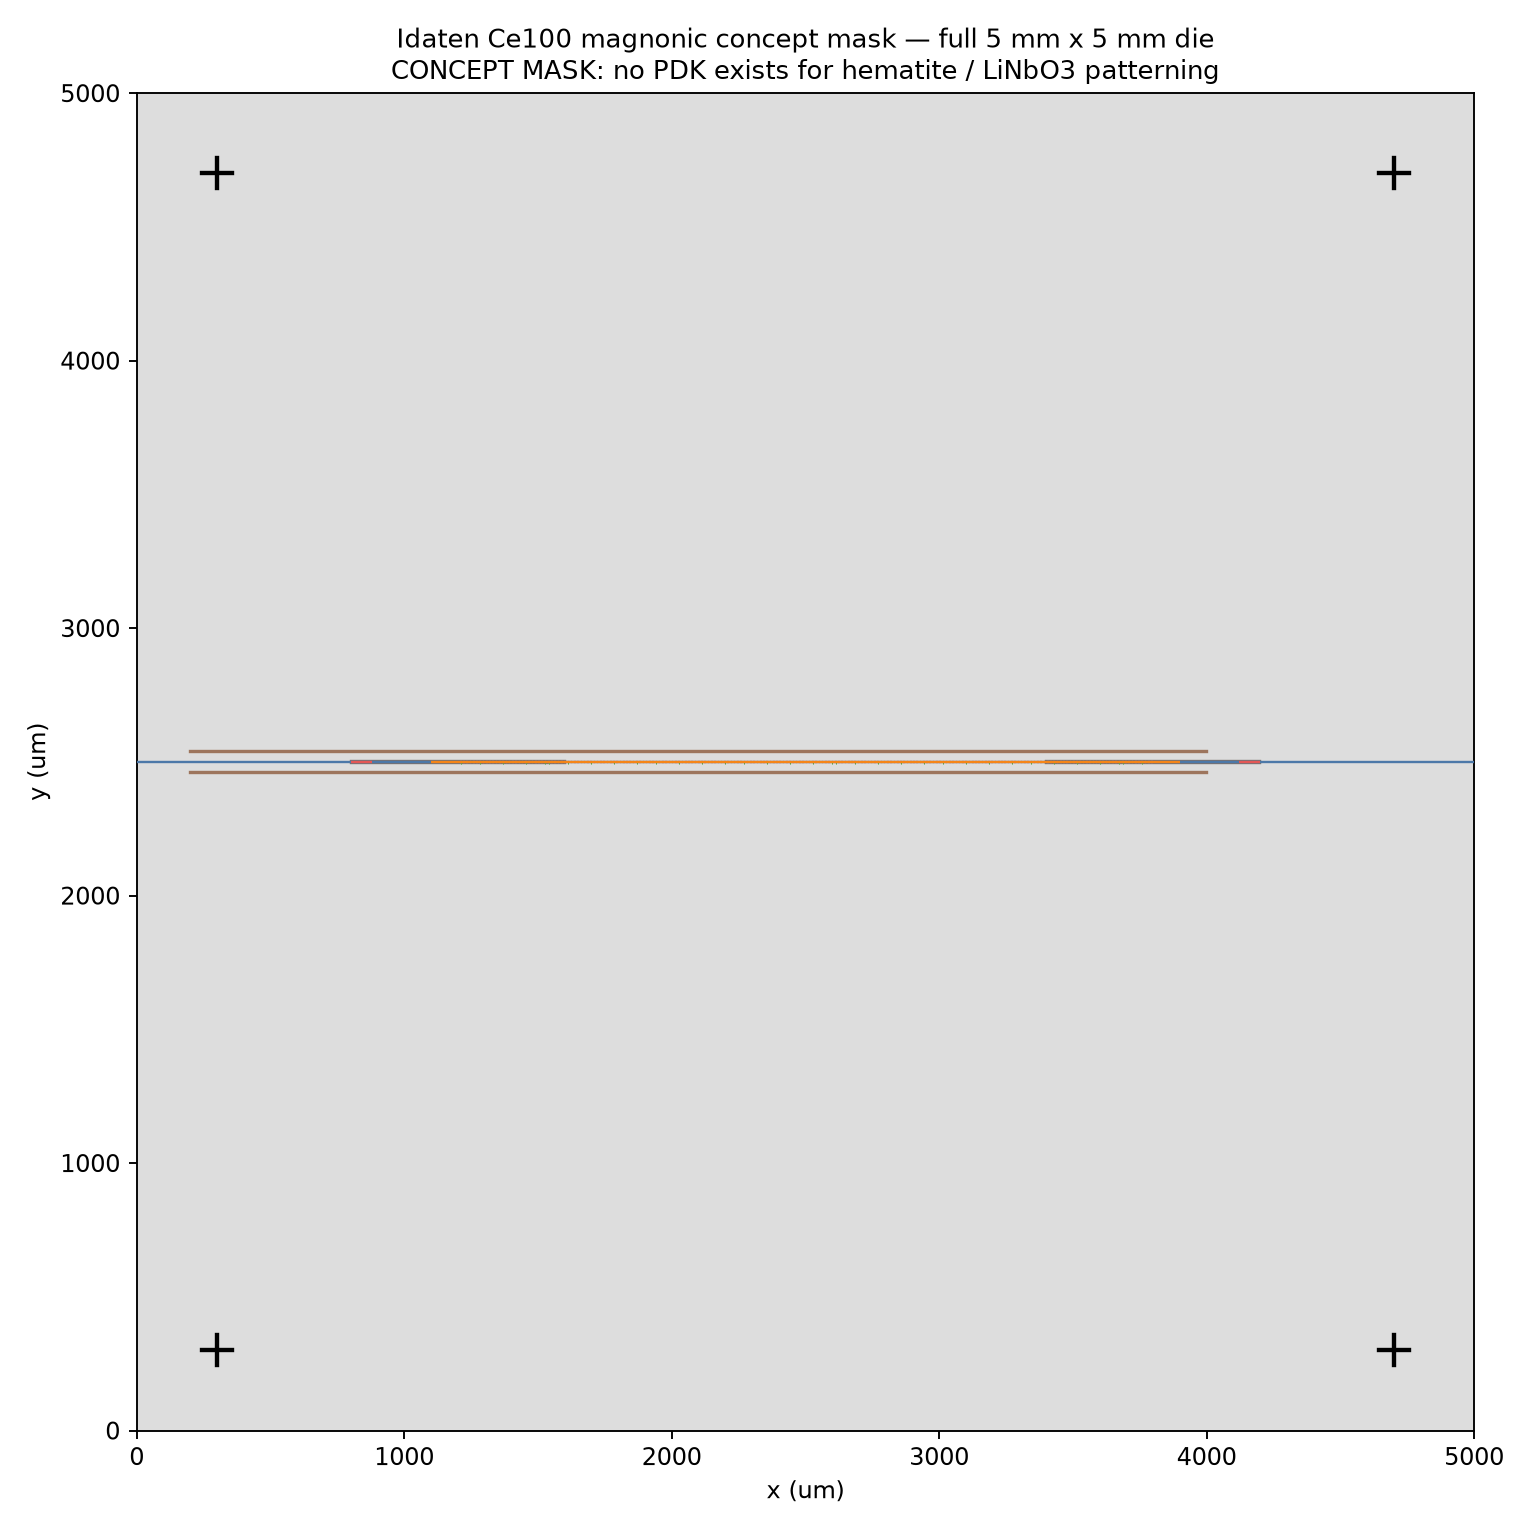

--- concept_mask_launch_zoom.png ---


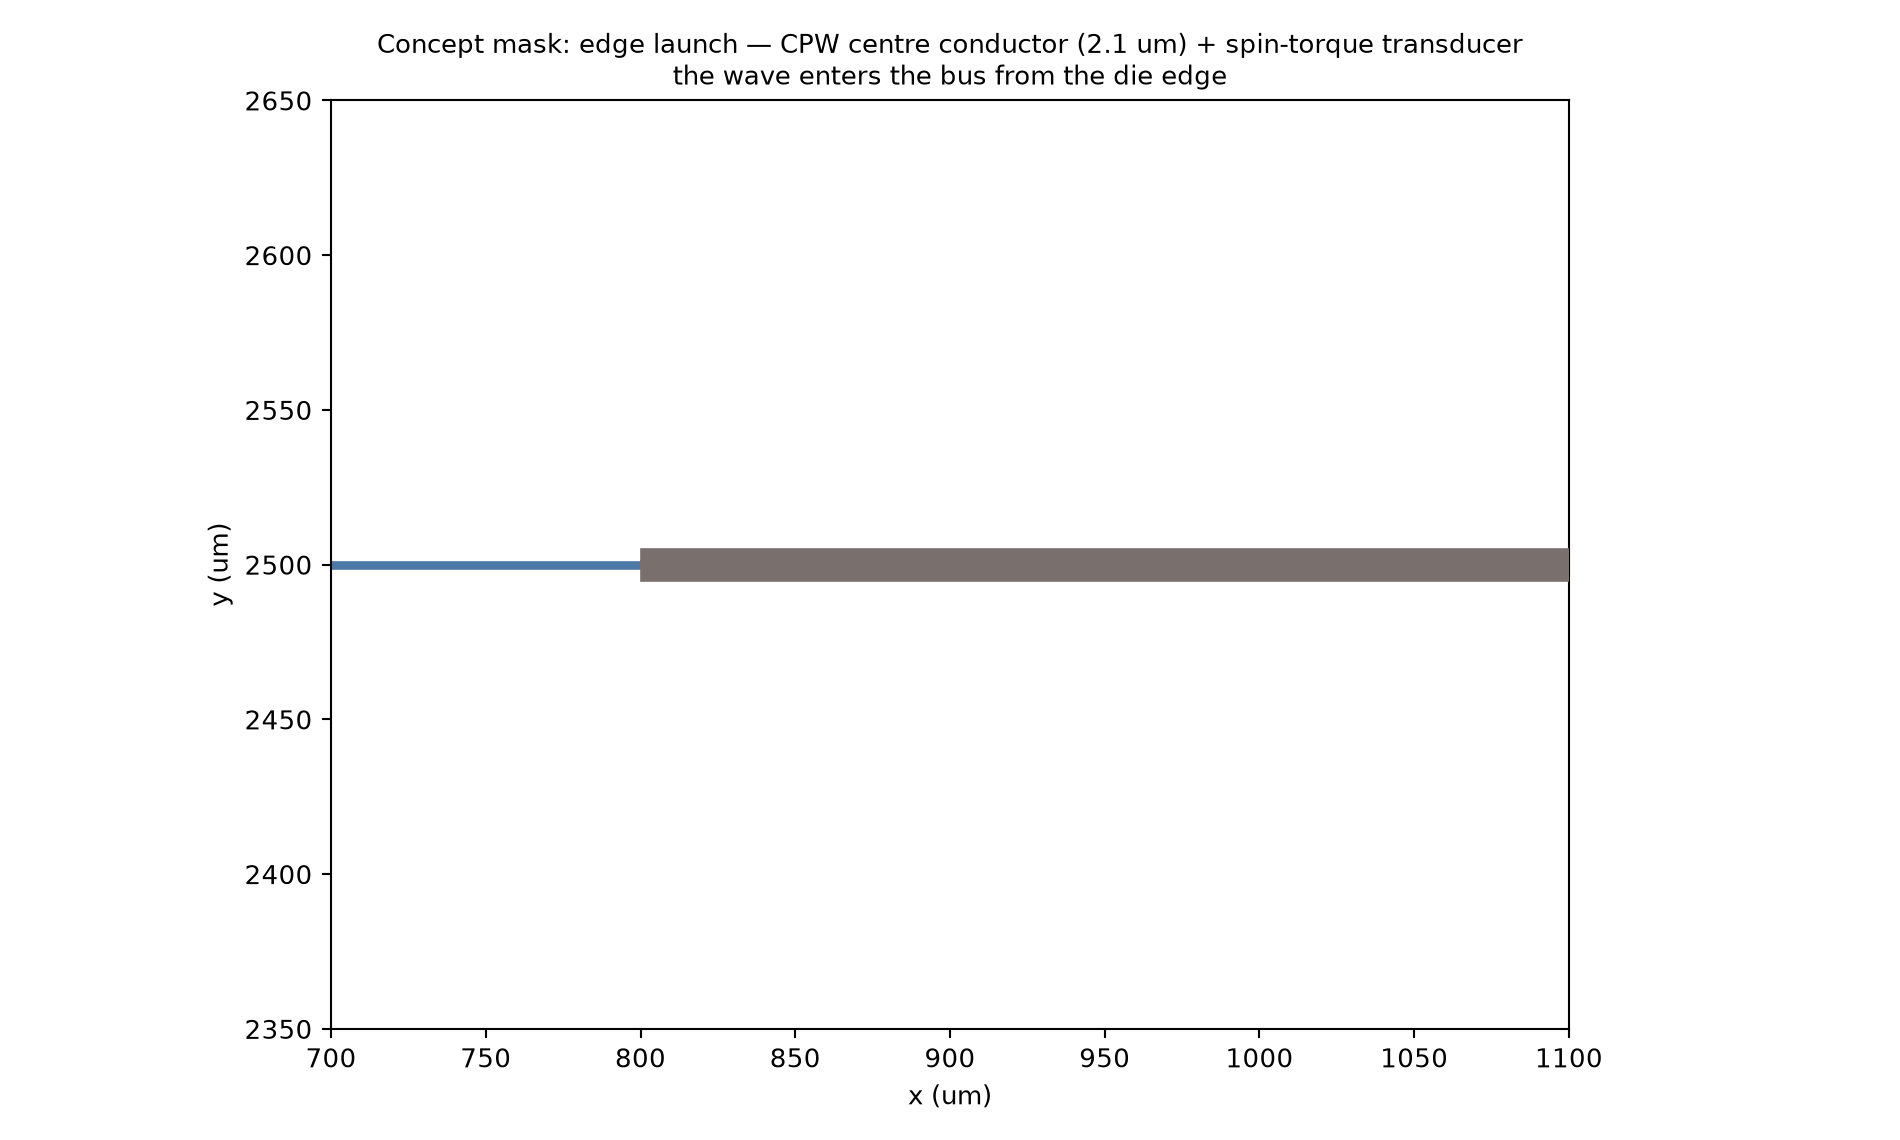

--- concept_mask_array_zoom_nm.png ---


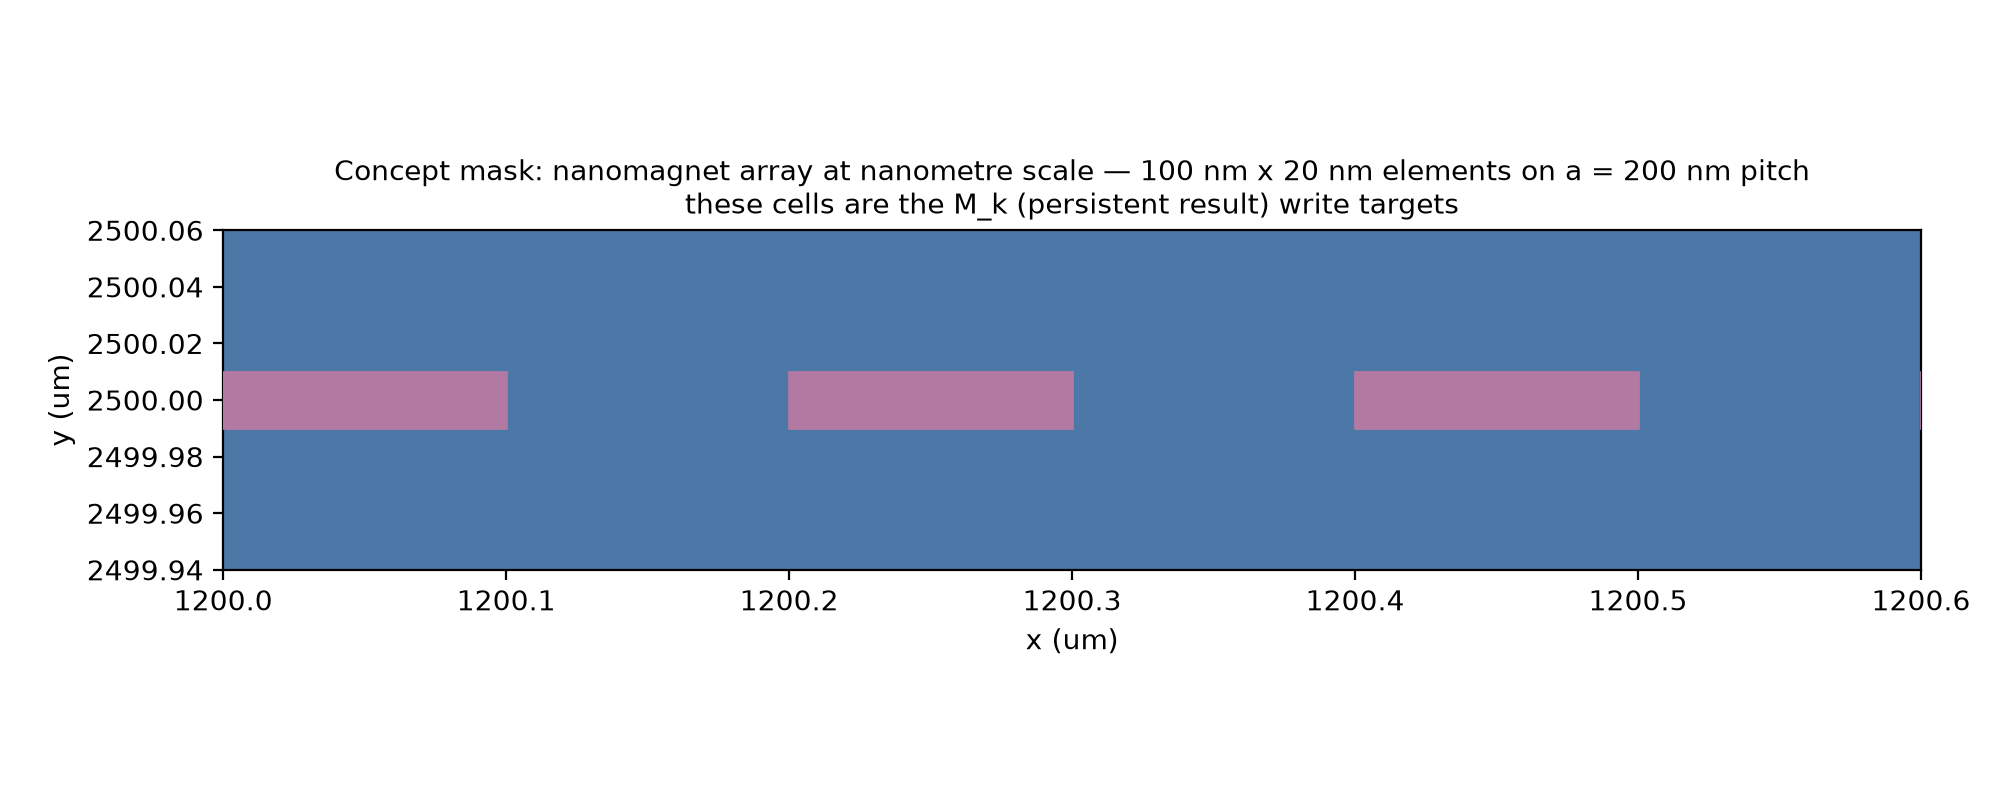

In [7]:

from IPython.display import Image, display
for fn in ("concept_mask_full_die.png",
           "concept_mask_launch_zoom.png",
           "concept_mask_array_zoom_nm.png"):
    p = REPO / "figures" / fn
    print(f"--- {fn} ---")
    display(Image(filename=str(p)))



## 4. The SKY130 open-flow layout

This cell reports the state of the second artifact, and it is written so that
it **cannot** silently pass if the artifact is missing.

The SKY130 layout is a **PDK-backed open-flow layout** produced by OpenROAD
Flow Scripts (ORFS) with the open-source SkyWater 130 nm PDK. It is the
physical instantiation of `P0` (the fixed switch/transistor topology) and the
`Ck` configuration switches - i.e. the *digital* tier of the architecture.

It is **not** the magnonic die. The magnonic die has no PDK; see §1.


In [8]:

sky = REPO / "gds" / "idaten_sky130"
if sky.exists() and any(sky.glob("*.gds")):
    print("SKY130 open-flow layout PRESENT:")
    for p in sorted(sky.iterdir()):
        print(f"   {p.name:<44} {p.stat().st_size/1e6:8.2f} MB")
    for g in sorted(sky.glob("*.gds")):
        l2 = db.Layout(); l2.read(str(g))
        print(f"\n{g.name}: top cell {l2.top_cell().name}, "
              f"{len(l2.layer_indices())} layers, dbu {l2.dbu}")
        for li in l2.layer_indices():
            info = l2.get_info(li)
            n = sum(1 for _ in l2.top_cell().begin_shapes_rec(li))
            print(f"   layer {info.layer:>3}/{info.datatype}: {n:>7} shapes")
else:
    print("SKY130 open-flow layout: NOT PRESENT in this checkout.")
    print("State the reason in the README; do not imply it exists.")
    print("Expected path:", sky)


SKY130 open-flow layout: NOT PRESENT in this checkout.
State the reason in the README; do not imply it exists.
Expected path: C:\Users\OSINOR TRILLIONS\Downloads\idaten-architecture\gds\idaten_sky130



## 5. What this notebook establishes

| Statement | Tag |
|---|---|
| The concept mask is generated from a script and is byte-reproducible | (S) |
| Its geometry passes a six-point audit read back from the GDS file itself | (S) |
| The nanomagnet array is 100 nm x 20 nm on a 200 nm pitch, 13 000 elements | (S) |
| The concept mask is a **manufacturable mask set** | **not claimed - no PDK exists for hematite / LiNbO3 patterning** |
| The SKY130 artifact is a PDK-backed open-flow layout | only if §4 finds the file; otherwise explicitly absent |
